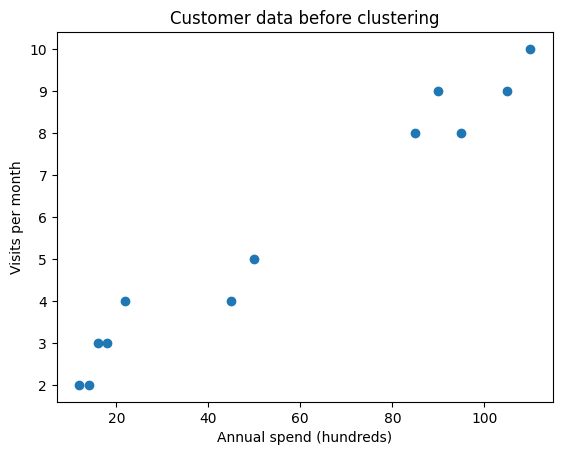

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [12, 18, 14, 22, 16, 85, 90, 95, 110, 105, 45, 50],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()

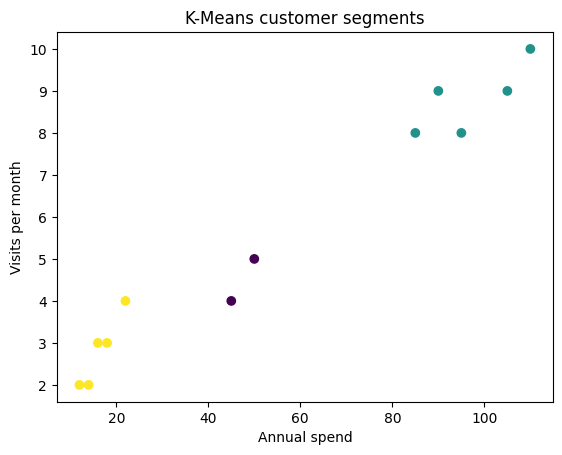

    AnnualSpend  VisitsPerMonth  Cluster
0            12               2        2
1            18               3        2
2            14               2        2
3            22               4        2
4            16               3        2
5            85               8        1
6            90               9        1
7            95               8        1
8           110              10        1
9           105               9        1
10           45               4        0
11           50               5        0


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)
km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()
print(customers)


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))


2 inertia: 2.58 silhouette: 0.756
3 inertia: 1.1 silhouette: 0.664
4 inertia: 0.64 silhouette: 0.537
5 inertia: 0.35 silhouette: 0.531


Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


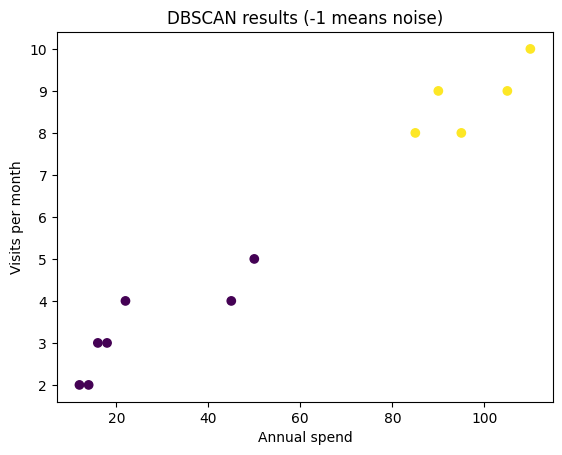

In [6]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)
print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()


Explained variance: [0.73  0.229]


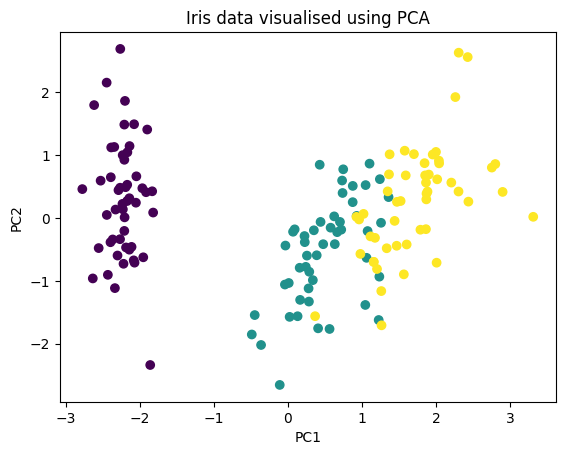

In [7]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)
print("Explained variance:",
      pca.explained_variance_ratio_.round(3))

plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()


In [9]:
from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [22, 3], [18, 2], [25, 3],
    [23, 4], [19, 3], [250, 20]
])
detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)
for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")

[22  3] Normal
[18  2] Normal
[25  3] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


Raw Customer Data:
    AnnualSpend  VisitsPerMonth
0            20               2
1            22               3
2            25               2
3            27               4
4            30               3
5            75               8
6            78               9
7            80               8
8            85              10
9            88               9
10           40               4
11           42               5


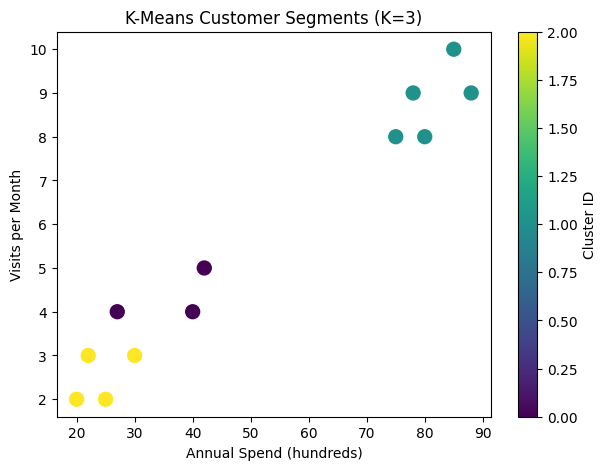


Cluster-wise Averages (K=3):
            AnnualSpend  VisitsPerMonth
Cluster_K3                             
0                 36.33            4.33
1                 81.20            8.80
2                 24.25            2.50

Model Evaluation Metrics (Elbow & Silhouette):
K=2 -> Inertia (Elbow): 2.03 | Silhouette Score: 0.786
K=3 -> Inertia (Elbow): 0.97 | Silhouette Score: 0.591
K=4 -> Inertia (Elbow): 0.66 | Silhouette Score: 0.449

DBSCAN Cluster Labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Number of noise points (-1): 0


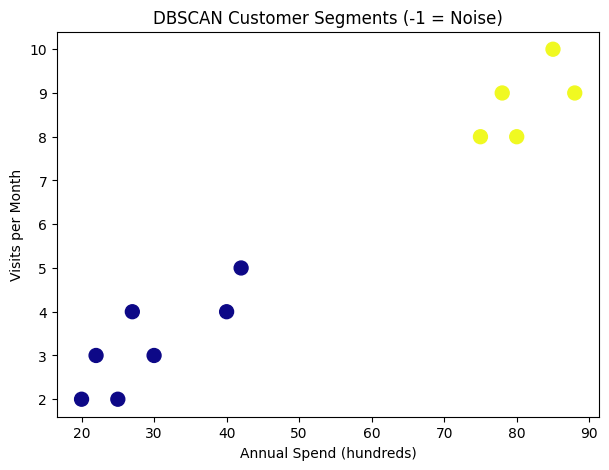

In [10]:
import os

os.environ["OMP_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Create the customer dataset
customers = pd.DataFrame({
    "AnnualSpend": [20, 22, 25, 27, 30, 75, 78, 80, 85, 88, 40, 42],
    "VisitsPerMonth": [2, 3, 2, 4, 3, 8, 9, 8, 10, 9, 4, 5],
})

print("Raw Customer Data:")
print(customers)

# 2. Scale the two features and run K-Means with K=3
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km3 = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster_K3"] = km3.fit_predict(X_scaled)

# 3. Visualise the K=3 clusters and compute cluster-wise averages
plt.figure(figsize=(7, 5))
plt.scatter(
    customers["AnnualSpend"],
    customers["VisitsPerMonth"],
    c=customers["Cluster_K3"],
    cmap="viridis",
    s=100,
)
plt.xlabel("Annual Spend (hundreds)")
plt.ylabel("Visits per Month")
plt.title("K-Means Customer Segments (K=3)")
plt.colorbar(label="Cluster ID")
plt.show()

cluster_summary = (
    customers.groupby("Cluster_K3")[["AnnualSpend", "VisitsPerMonth"]]
    .mean()
    .round(2)
)
print("\nCluster-wise Averages (K=3):")
print(cluster_summary)

# 4. Try K=2, 3, and 4 and compare Elbow (inertia) and Silhouette scores
print("\nModel Evaluation Metrics (Elbow & Silhouette):")
for k in [2, 3, 4]:
  model = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = model.fit_predict(X_scaled)
  inertia = round(model.inertia_, 2)
  sil_score = round(silhouette_score(X_scaled, labels), 3)
  print(
      f"K={k} -> Inertia (Elbow): {inertia} | Silhouette Score: {sil_score}"
  )

# 5. Run DBSCAN and visualise results (-1 indicates noise)
db = DBSCAN(eps=0.8, min_samples=2)
customers["Cluster_DBSCAN"] = db.fit_predict(X_scaled)

print("\nDBSCAN Cluster Labels:", customers["Cluster_DBSCAN"].values)
print("Number of noise points (-1):", sum(customers["Cluster_DBSCAN"] == -1))

plt.figure(figsize=(7, 5))
plt.scatter(
    customers["AnnualSpend"],
    customers["VisitsPerMonth"],
    c=customers["Cluster_DBSCAN"],
    cmap="plasma",
    s=100,
)
plt.xlabel("Annual Spend (hundreds)")
plt.ylabel("Visits per Month")
plt.title("DBSCAN Customer Segments (-1 = Noise)")
plt.show()